# Лабораторна робота № 2 — Індивідуальне завдання
## Елементарний перцептрон: α- та γ-системи підкріплень

**Самостійний робочий ноутбук.** Цей файл містить **лише частину з індивідуальним завданням**, вправами, перевірками та звітом — без розгорнутого теоретичного викладу й відтворення прикладу Н/П з повного ноутбука. Код, який потрібний для незалежного запуску завдань, залишено в розділі «Допоміжні функції».

**За оригінальним PDF (розд. 2.3, стор. 28–29) потрібно:**

1. Побудувати елементарний перцептрон, який розпізнає **перші дві букви вашого імені та прізвища**. Обґрунтувати: число S-рецепторів (**12–30**), число A-нейронів, крок навчання, функції активації і пороги на кожному шарі.
2. Навчити мережу за **α- і γ-системами підкріплень** та порівняти результати.

**Звіт за PDF (розд. 2.4, стор. 29):** тема, індивідуальне завдання, результати його виконання, розгорнутий висновок.

**Запропонована реалізація для лабораторної:** решітка 5×5 (**25 S-елементів**), чотири асоціативні детектори (**4 A**) та **4 незалежні біполярні R-класифікатори** за схемою one-vs-rest. Це дидактичне розширення базової архітектури з *одним* R-нейроном; поясніть відмінність у звіті. У PDF не вказано конкретні гліфи й кількість нейронів прихованого шару — їх слід обґрунтувати самостійно.

**Інструкція:** запускайте всі клітинки зверху донизу. У завданнях `TODO` змінюйте параметри, виконуйте експерименти та фіксуйте власні висновки. Потрібні: `numpy`, `pandas`, `matplotlib`, `IPython` (GPU та інтернет не потрібні).

## 0. Середовище та допоміжні функції

Нижченаведені функції потрібні для **автономного запуску** практичних клітинок. Вони не є окремим пунктом індивідуального завдання з PDF.

**Правила навчання при помилці:**

- α: змінюємо ваги активних зв’язків і обмежуємо їх діапазоном $[0,1]$;
- γ: враховуємо активні й пасивні зв’язки, підтримуємо незмінність суми ваг $\Sigma$ і межі $[0,1]$.

У наведеній реалізації використано проєкцію на множину $\{w\in[0,1]^n : \sum w_i = \Sigma_0\}$, щоб коректно враховувати крайні значення ваг.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.precision', 4)
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams['font.family'] = 'DejaVu Sans'  # кирилиця
print('NumPy:', np.__version__, '| Готово до роботи')

NumPy: 2.4.2 | Готово до роботи


In [2]:
def bipolar_step(u, threshold):
    """R-нейрон: рівність порогу відноситься до класу +1 (з допуском округлення)."""
    return np.where(np.asarray(u) >= np.asarray(threshold) - 1e-12, 1, -1)


def associative_layer(S, W_sa, theta_a):
    """S: (samples, pixels); W_sa: (neurons, pixels); theta_a: (neurons,)."""
    S = np.atleast_2d(np.asarray(S, dtype=float))
    W_sa = np.asarray(W_sa, dtype=float)
    theta_a = np.asarray(theta_a, dtype=float)
    z = S @ W_sa.T
    return z, (z >= theta_a[None, :] - 1e-12).astype(int)


def preview_patterns(patterns, labels, title='Вхідні зображення'):
    fig, axes = plt.subplots(1, len(patterns), figsize=(2.6 * len(patterns), 3))
    axes = np.atleast_1d(axes)
    for ax, letter, mat in zip(axes, labels, patterns):
        ax.imshow(mat, cmap='Greys', vmin=0, vmax=1, interpolation='nearest')
        ax.set_title(f'Літера «{letter}»')
        ax.set_xticks([]); ax.set_yticks([])
        for k in np.arange(-.5, mat.shape[0], 1): ax.axhline(k, color='gray', lw=.5)
        for k in np.arange(-.5, mat.shape[1], 1): ax.axvline(k, color='gray', lw=.5)
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

In [3]:
def project_box_fixed_sum(v, total, iterations=90):
    """Евклідова проєкція на {w: 0<=w<=1, sum(w)=total}."""
    v = np.asarray(v, dtype=float)
    if v.ndim != 1 or len(v) == 0 or not (0 <= total <= len(v)):
        raise ValueError('Недопустимі розміри або сумарна вага')
    if np.isclose(total, 0.0): return np.zeros_like(v)
    if np.isclose(total, float(len(v))): return np.ones_like(v)
    lo, hi = float(np.min(v) - 1.), float(np.max(v))
    for _ in range(iterations):
        mid = (lo + hi) / 2
        if np.clip(v - mid, 0, 1).sum() > total:
            lo = mid
        else:
            hi = mid
    return np.clip(v - (lo + hi)/2, 0, 1)


def update_weights(w, activation, wanted, predicted, lr=0.1, method='alpha'):
    """Один крок навчання ОДНОГО бінарного вихідного R-нейрона."""
    w = np.asarray(w, dtype=float).copy()
    a = np.asarray(activation, dtype=int)
    if len(w) != len(a): raise ValueError('Число ваг і A-нейронів має збігатися')
    if method not in ('alpha', 'gamma'): raise ValueError("method: 'alpha' або 'gamma'")
    if lr <= 0: raise ValueError('lr має бути додатним')
    if predicted == wanted: return w
    eta = lr * int(wanted)
    if method == 'alpha':
        return np.clip(w + eta*a, 0., 1.)
    proposal = w + eta*(a - a.mean())
    return project_box_fixed_sum(proposal, total=w.sum())


def predict_binary(A, w, threshold):
    return bipolar_step(np.asarray(A) @ np.asarray(w), threshold)


def train_binary(A, y, w_init, threshold, method='alpha', lr=.1,
                 max_epochs=60, sample_order=None):
    """Одна вага-векторна R-модель; лог після кожного пред'явлення."""
    A = np.asarray(A,dtype=int); y=np.asarray(y,dtype=int)
    w = np.asarray(w_init, dtype=float).copy()
    indices = range(len(y)) if sample_order is None else sample_order
    trace = [dict(step=0, epoch=0, sample='—', corrected=False, sum_w=w.sum(),
                  weights=w.copy(), n_errors=int(np.sum(predict_binary(A,w,threshold)!=y)))]
    step=0
    for epoch in range(1,max_epochs+1):
        for idx in indices:
            pred=int(predict_binary(A[idx],w,threshold))
            modified = pred != y[idx]
            w = update_weights(w, A[idx], y[idx], pred, lr, method)
            step+=1
            trace.append(dict(step=step,epoch=epoch,sample=int(idx),corrected=modified,
                              sum_w=w.sum(),weights=w.copy(),
                              n_errors=int(np.sum(predict_binary(A,w,threshold)!=y))))
        if np.array_equal(predict_binary(A,w,threshold),y):
            break
    return w, pd.DataFrame(trace), epoch

# Самоперевірка математичних властивостей.
tmp = project_box_fixed_sum(np.array([-3., .3, 2., .7]), total=1.8)
assert np.all((tmp>=-1e-10)&(tmp<=1+1e-10)) and abs(tmp.sum()-1.8)<1e-9
for a_test in ([1,0,1,0],[1,1,0,0],[1,0,0,0]):
    original=np.array([.2,.8,.6,.9]); y_test=-1
    adjusted=update_weights(original,a_test,y_test,predicted=1,method='gamma')
    assert abs(adjusted.sum()-original.sum()) < 1e-9
print('Тести для корекцій і збереження суми γ: OK')

Тести для корекцій і збереження суми γ: OK


## 1. Індивідуальна робота: чотири літери вашого імені та прізвища

**Завдання з PDF, стор. 28–29:** обґрунтувати (1) кількість $S$-нейронів у діапазоні **12–30**, (2) розмір асоціативного шару, (3) крок навчання, (4) функції активації, (5) пороги; навчити α/γ і порівняти.

**Конструкція для початку:** поле **5×5** → **25 S**; по одному **A-детектору на кожну з чотирьох літер** → **4 A**; **4 незалежні біполярні R-нейрони** («літера k» проти «не літера k»). Для кожного A-нейрона параметри $W_{SA}$ та $\theta_A$ сконструйовано на основі еталонного зображення так, щоб **саме цей зразок** його активував; це окремий навчальний варіант на основі ідеї теореми Розенблатта (стор. 23–24), а **не** випадкова матриця з прикладу Н/П.

> **TODO 1.** У наступній клітинці замініть **ім'я** та **прізвище** на власні. Бажано, щоб чотири перші літери були різними. Для повторених літер потрібна домовленість про класи: за самою лише чорно-білою картинкою не можна відрізнити два однакові символи.

In [4]:
# TODO 1: змініть на власні ім'я та прізвище (українськими літерами)
FIRST_NAME = 'Родіон'
LAST_NAME  = 'Остапенко'

LETTERS = list(FIRST_NAME.upper()[:2] + LAST_NAME.upper()[1:3])
assert len(LETTERS) == 4, 'Введіть щонайменше 2 символи у кожному рядку'
print('Розпізнаємо:', LETTERS)
if len(set(LETTERS))<4:
    raise ValueError('Є повтори серед 4 літер. Замініть приклад або обґрунтуйте інше маркування класів.')

Розпізнаємо: ['Р', 'О', 'С', 'Т']


### 1.1. Набір растрових гліфів 5×5

Показані спрощені навчальні **шаблони**, а не готовий шрифт; `1` — заповнена клітинка, `0` — порожня. Можете змінювати/додавати шаблони у словник `FONT_5X5`, головне зберегти 5 рядків по 5 символів `0`/`1`. Гліфи схематичні: форма може не збігатися з типографським написанням.

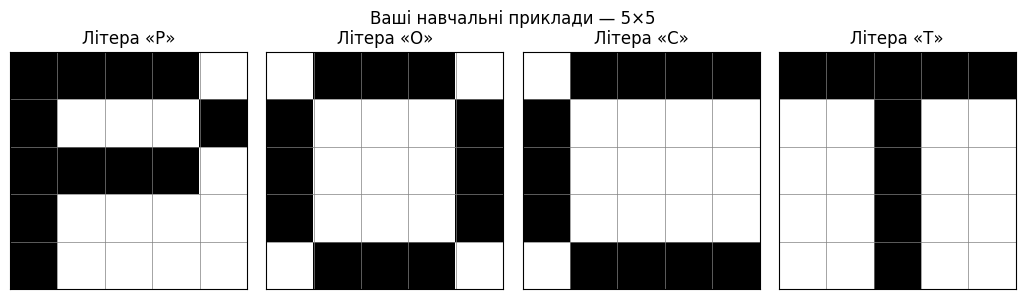

Вхідних рецепторів S: 25


In [5]:
# Спрощені растрові літери української абетки — можна редагувати власноруч.
FONT_5X5 = {
 'А': ['01110','10001','11111','10001','10001'],
 'Б': ['11111','10000','11110','10001','11110'],
 'В': ['11110','10001','11110','10001','11110'],
 'Г': ['11111','10000','10000','10000','10000'],
 'Ґ': ['00001','11111','10000','10000','10000'],
 'Д': ['01110','01010','01010','11111','10001'],
 'Е': ['11111','10000','11110','10000','11111'],
 'Є': ['01111','10000','11110','10000','01111'],
 'Ж': ['10101','10101','01110','10101','10101'],
 'З': ['11110','00001','01110','00001','11110'],
 'И': ['10001','10011','10101','11001','10001'],
 'І': ['01110','00100','00100','00100','01110'],
 'Ї': ['01010','00000','00100','00100','00100'],
 'Й': ['10101','01010','10011','11001','10001'],
 'К': ['10001','10010','11100','10010','10001'],
 'Л': ['00111','01001','01001','10001','10001'],
 'М': ['10001','11011','10101','10001','10001'],
 'Н': ['10001','10001','11111','10001','10001'],
 'О': ['01110','10001','10001','10001','01110'],
 'П': ['11111','10001','10001','10001','10001'],
 'Р': ['11110','10001','11110','10000','10000'],
 'С': ['01111','10000','10000','10000','01111'],
 'Т': ['11111','00100','00100','00100','00100'],
 'У': ['10001','10001','01111','00001','11110'],
 'Ф': ['00100','01110','10101','01110','00100'],
 'Х': ['10001','01010','00100','01010','10001'],
 'Ц': ['10010','10010','10010','11111','00001'],
 'Ч': ['10001','10001','01111','00001','00001'],
 'Ш': ['10101','10101','10101','10101','11111'],
 'Щ': ['10101','10101','10101','11111','00001'],
 'Ь': ['10000','10000','11110','10001','11110'],
 'Ю': ['10111','10101','11101','10101','10111'],
 'Я': ['01111','10001','01111','00101','11001'],
}

for letter, glyph in FONT_5X5.items():
    assert len(glyph)==5 and all(len(s)==5 and set(s)<={'0','1'} for s in glyph), f'Некоректна матриця: {letter}'


def glyph_matrix(letter):
    if letter not in FONT_5X5:
        raise ValueError(f'Немає шаблону для {letter!r}. Додайте його до FONT_5X5.')
    return np.asarray([[int(pixel) for pixel in row] for row in FONT_5X5[letter]],dtype=int)

IMAGES = np.stack([glyph_matrix(ch) for ch in LETTERS])
assert IMAGES.shape == (4,5,5)
assert len({tuple(img.flat) for img in IMAGES})==4, 'Однакові матриці гліфів: змініть форми літер'
preview_patterns(IMAGES, LETTERS, 'Ваші навчальні приклади — 5×5')
print('Вхідних рецепторів S:',IMAGES.shape[1]*IMAGES.shape[2])

### 1.2. Як задати фіксовані зв'язки S→A

Для кожного гліфа $k$ побудуємо **детектор точного збігу**:

- $w^{SA}_{kj}=+1$, коли в еталоні піксель $j$ чорний;
- $w^{SA}_{kj}=-1$, коли піксель $j$ білий;
- $\theta_{A_k}$ — кількість чорних пікселів у еталонному зображенні $k$.

Тоді власний шаблон дає точно $\sum_j w_{kj}^{SA}s_j=\theta_{A_k}$, а відмінний від нього принаймні в одному біті має меншу суму. Вихід $A_k=1$ тільки для **точної відповідності**. Це зручно для перевірки формул, але погано переносить зашумлення; в експериментах ми це покажемо.

**Активації:** S — тотожна (0/1); A — ступінчаста (0/1); R — біполярна (−1/+1). **Поріг R:** $\theta_R=0.5$ для всіх 4 бінарних класифікаторів, бо ваги A→R обмежено інтервалом $[0,1]$.

In [6]:
X = IMAGES.reshape(4,25)    # зображення -> вектор S з 25 елементів
W_SA = np.where(X==1,1.0,-1.0)  # 4 A-детектори x 25 S
THETA_A = X.sum(axis=1).astype(float)
THETA_R = 0.5
LEARNING_RATE=0.1
Z,A = associative_layer(X,W_SA,THETA_A)

summary = pd.DataFrame({'Літера': LETTERS,
                        'Поріг A':THETA_A.astype(int),
                        'Активних A':A.sum(axis=1),
                        'Збуджений нейрон': [f'A{j+1}' for j in A.argmax(axis=1)]})
display(summary)
display(pd.DataFrame(A,index=LETTERS,columns=[f'A{i+1}' for i in range(4)]))
assert W_SA.shape == (4,25)
assert np.array_equal(A,np.eye(4,dtype=int)), 'Не отримано очікувані унікальні ознаки'
print('Параметри: 25 S, 4 A, 4 незалежні бінарні R; α/γ-крок =',LEARNING_RATE)

,Літера,Поріг A,Активних A,Збуджений нейрон
0,Р,12,1,A1
1,О,12,1,A2
2,С,11,1,A3
3,Т,9,1,A4


,A1,A2,A3,A4
Р,1,0,0,0
О,0,1,0,0
С,0,0,1,0
Т,0,0,0,1


Параметри: 25 S, 4 A, 4 незалежні бінарні R; α/γ-крок = 0.1


### 1.3. Чотири незалежні R-класифікатори

Для цілі $k$ істинна мітка $y_{jk}=+1$, коли $j=k$ і $-1$ в усіх інших випадках. Для кожного виходу $k$ навчаємо власний вектор $w^{AR}_{:,k}$ за тим самим алгоритмом, що і в розділі 3. На виході маємо 4 біполярні сигнали. Клас визначено **однозначно**, лише якщо *рівно один* R-нейрон має сигнал +1. Інакше результат — **невідомий/неоднозначний** (це коректніше, ніж довільно брати `argmax` при всіх −1).

In [7]:
Y = 2*np.eye(4,dtype=int)-1  # +1 на правильному класі, -1 на решті
W_R_INITIAL = np.full((A.shape[1],len(LETTERS)),0.5)  # A x R, одні й ті самі ваги

def predict_multi(A_in,W,theta=THETA_R):
    """Кожний стовпець W відповідає незалежному елементарному R-класифікатору."""
    return bipolar_step(np.asarray(A_in)@np.asarray(W),theta)


def decode_outputs(outputs,labels):
    result=[]
    for row in np.atleast_2d(outputs):
        winners=np.flatnonzero(row==1)
        result.append(labels[winners[0]] if len(winners)==1 else 'Невідомо/неоднозначно')
    return result


def train_multi(A_in, Y_target, initial, lr=.1, method='alpha', max_epochs=100):
    A_in=np.asarray(A_in,dtype=int);Y_target=np.asarray(Y_target,dtype=int)
    W=np.asarray(initial,dtype=float).copy()
    assert W.shape == (A_in.shape[1],Y_target.shape[1])
    history=[]; updates=0; sums=[W.sum(axis=0).copy()]
    for epoch in range(1,max_epochs+1):
        errors_before=int(np.count_nonzero(predict_multi(A_in,W)!=Y_target))
        this_updates=0
        for i in range(len(A_in)):
            for k in range(Y_target.shape[1]):
                pred = int(predict_binary(A_in[i],W[:,k], THETA_R))
                expected = int(Y_target[i,k])
                if pred != expected:
                    W[:,k] = update_weights(W[:,k],A_in[i],expected,pred,lr,method)
                    updates += 1; this_updates += 1
        errs_after=int(np.count_nonzero(predict_multi(A_in,W)!=Y_target))
        history.append({'Епоха':epoch,'Помилки до':errors_before,
                        'Помилки після':errs_after,'Оновлень за епоху':this_updates})
        sums.append(W.sum(axis=0).copy())
        if errs_after==0:break
    return W,pd.DataFrame(history),np.vstack(sums),updates

W_ALPHA, LOG_ALPHA, SUM_ALPHA, NUM_ALPHA = train_multi(A,Y,W_R_INITIAL,lr=LEARNING_RATE,method='alpha')
W_GAMMA, LOG_GAMMA, SUM_GAMMA, NUM_GAMMA = train_multi(A,Y,W_R_INITIAL,lr=LEARNING_RATE,method='gamma')

assert np.array_equal(predict_multi(A,W_ALPHA),Y), 'α-модель не навчилася'
assert np.array_equal(predict_multi(A,W_GAMMA),Y), 'γ-модель не навчилася'
assert np.allclose(SUM_GAMMA,SUM_GAMMA[0],atol=1e-9), 'γ не зберегла суму ваг'

metrics=[]
for meth,W,log,sums,count in [('α',W_ALPHA,LOG_ALPHA,SUM_ALPHA,NUM_ALPHA),
                               ('γ',W_GAMMA,LOG_GAMMA,SUM_GAMMA,NUM_GAMMA)]:
    pred=predict_multi(A,W)
    metrics.append({'Метод':meth,'Епох':len(log),'Оновлень R-ваг':count,
                    'Вірних бінарних відповідей':f'{np.sum(pred==Y)}/{Y.size}',
                    'Вірно розпізнаних літер':f'{sum(p==t for p,t in zip(decode_outputs(pred,LETTERS),LETTERS))}/4',
                    'Макс. відхилення Σ від початку':np.max(np.abs(sums-sums[0]))})
METRICS=pd.DataFrame(metrics)
display(METRICS)
print('Мітки:', LETTERS)
print('α-прогнози:',decode_outputs(predict_multi(A,W_ALPHA),LETTERS))
print('γ-прогнози:',decode_outputs(predict_multi(A,W_GAMMA),LETTERS))

,Метод,Епох,Оновлень R-ваг,Вірних бінарних відповідей,Вірно розпізнаних літер,Макс. відхилення Σ від початку
0,α,1,12,16/16,4/4,3.0000e-01
1,γ,1,12,16/16,4/4,1.3323e-15


Мітки: ['Р', 'О', 'С', 'Т']
α-прогнози: ['Р', 'О', 'С', 'Т']
γ-прогнози: ['Р', 'О', 'С', 'Т']


### 1.4. Графічний аналіз вивчених ваг і перебігу навчання

Зіставте, які ваги збільшились, які зменшились і чому для γ-системи сума ваг **кожного** R-нейрона не змінилася. Порівняння «швидший метод» коректне **лише для даних 4 літер, стартових ваг та кроку**, а не для всіх задач.

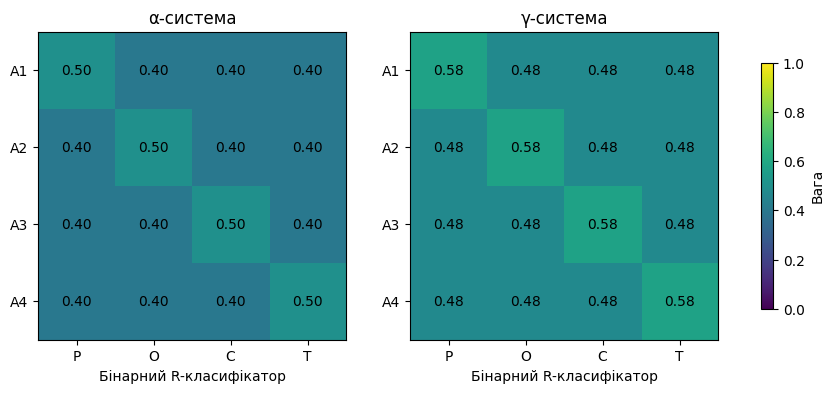

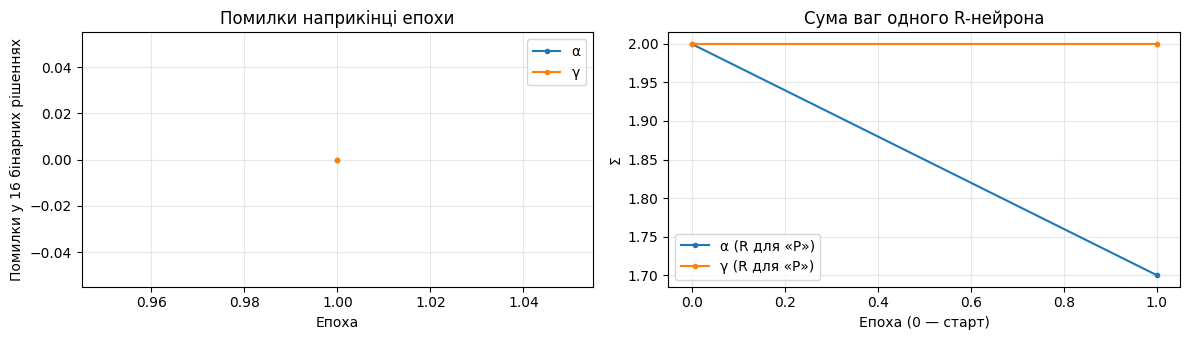

In [8]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,W,kind in zip(axs,[W_ALPHA,W_GAMMA],['α-система','γ-система']):
    image=ax.imshow(W,vmin=0,vmax=1,cmap='viridis')
    ax.set_xticks(range(4),LETTERS);ax.set_yticks(range(4),[f'A{i+1}' for i in range(4)])
    ax.set_xlabel('Бінарний R-класифікатор');ax.set_title(kind)
    for i in range(4):
        for j in range(4):
            ax.text(j,i,f'{W[i,j]:.2f}',ha='center',va='center',color='white' if W[i,j]<.25 else 'black')
fig.colorbar(image,ax=axs.ravel().tolist(),shrink=.8,label='Вага')
plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for label,log in [('α',LOG_ALPHA),('γ',LOG_GAMMA)]:
    axes[0].plot(log['Епоха'],log['Помилки після'],'.-',label=label)
axes[0].set_title('Помилки наприкінці епохи')
axes[0].set_xlabel('Епоха');axes[0].set_ylabel('Помилки у 16 бінарних рішеннях')
for label,sums in [('α',SUM_ALPHA),('γ',SUM_GAMMA)]:
    axes[1].plot(range(len(sums)),sums[:,0],'.-',label=f'{label} (R для «{LETTERS[0]}»)')
axes[1].set_title('Сума ваг одного R-нейрона')
axes[1].set_xlabel('Епоха (0 — старт)');axes[1].set_ylabel('Σ')
for ax in axes: ax.grid(alpha=.3);ax.legend()
plt.tight_layout();plt.show()

## 2. Додаткові дослідницькі завдання (для висновків)

### 2.1. Залежність навчання від кроку $\varepsilon$

Проведіть навчання для **$\varepsilon\in\{0.02,0.05,0.10,0.20\}$** (можете додати власні значення). **TODO 2:** сформулюйте, як крок впливає на кількість корекцій, чи зберігається $\Sigma$ у γ-системі та чи однакова тенденція для α/γ.

> **Ці експерименти запропоновано як додаткову практику:** оригінальний PDF вимагає порівняти α та γ, але не встановлює саме такі значення кроку.

,Крок η,Система,Епох,Оновлень,Помилок,Макс. |ΔΣ|
0,0.02,α,1,12,0,6.0000e-02
1,0.02,γ,1,12,0,4.4409e-16
2,0.05,α,1,12,0,1.5000e-01
3,0.05,γ,1,12,0,8.8818e-16
4,0.10,α,1,12,0,3.0000e-01
5,0.10,γ,1,12,0,1.3323e-15
6,0.20,α,1,12,0,6.0000e-01
7,0.20,γ,1,12,0,4.4409e-16


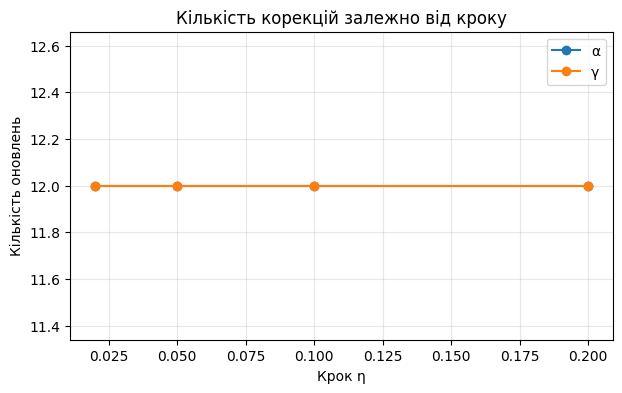

In [9]:
rates=[0.02,0.05,0.10,0.20]
experiments=[]
for eta in rates:
    for method in ['alpha','gamma']:
        result,logs,sums,updates=train_multi(A,Y,W_R_INITIAL,lr=eta,method=method)
        experiments.append({'Крок η':eta,'Система':'α' if method=='alpha' else 'γ',
                            'Епох':len(logs),'Оновлень':updates,
                            'Помилок':int(np.count_nonzero(predict_multi(A,result)!=Y)),
                            'Макс. |ΔΣ|':np.max(np.abs(sums-sums[0]))})
EXPERIMENTS=pd.DataFrame(experiments)
display(EXPERIMENTS)
fig,ax=plt.subplots(figsize=(7,4))
for label,group in EXPERIMENTS.groupby('Система'):
    ax.plot(group['Крок η'],group['Оновлень'],'o-',label=label)
ax.set_xlabel('Крок η');ax.set_ylabel('Кількість оновлень')
ax.set_title('Кількість корекцій залежно від кроку')
ax.grid(alpha=.3);ax.legend();plt.show()

### 2.2. Шум у зображеннях: один змінений піксель

Порогові A-детектори з цього прикладу налаштовані на **точний збіг**. Що станеться, якщо випадково змінити один піксель? Тут маємо невеликий приклад **перевірки стійкості без перенавчання**.

**TODO 3.** Поясніть, чому модель може вивести «невідомо» навіть при зміні лише одного пікселя. Запропонуйте хоча б один спосіб підвищення стійкості: нові приклади, нові A-детектори чи інші пороги.

,Справжня літера,Змінений індекс S (1..25),Кількість активних A,α-прогноз,γ-прогноз
0,Р,22,0,Невідомо/неоднозначно,Невідомо/неоднозначно
1,О,5,0,Невідомо/неоднозначно,Невідомо/неоднозначно
2,С,1,0,Невідомо/неоднозначно,Невідомо/неоднозначно
3,Т,16,0,Невідомо/неоднозначно,Невідомо/неоднозначно


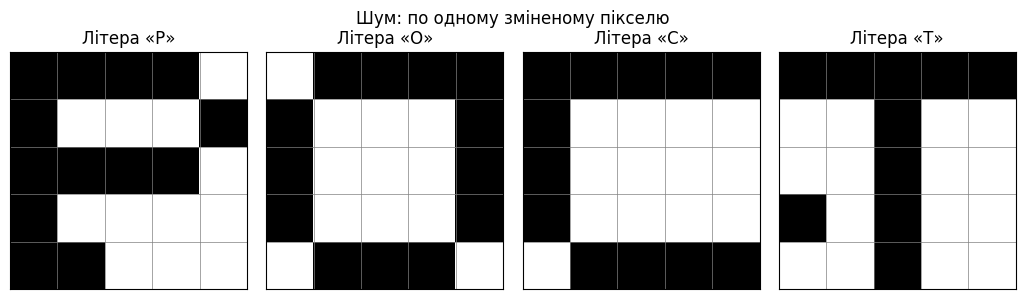

In [10]:
def corrupt_one_pixel(X_flat,random_seed=2026):
    r=np.random.default_rng(random_seed)
    damaged=np.asarray(X_flat).copy()
    flip_indices=[]
    for i in range(len(damaged)):
        j=int(r.integers(0,damaged.shape[1]))
        damaged[i,j]=1-damaged[i,j]
        flip_indices.append(j)
    return damaged,flip_indices

X_NOISY,CHANGED=corrupt_one_pixel(X)
_,A_NOISY=associative_layer(X_NOISY,W_SA,THETA_A)
result_noise=pd.DataFrame({
    'Справжня літера':LETTERS,
    'Змінений індекс S (1..25)':np.asarray(CHANGED)+1,
    'Кількість активних A':A_NOISY.sum(axis=1),
    'α-прогноз':decode_outputs(predict_multi(A_NOISY,W_ALPHA),LETTERS),
    'γ-прогноз':decode_outputs(predict_multi(A_NOISY,W_GAMMA),LETTERS)})
display(result_noise)
preview_patterns(X_NOISY.reshape(4,5,5),LETTERS,'Шум: по одному зміненому пікселю')

### 2.3. Консервативність γ-системи: коли вона може завадити

Теорема 2.6 (стор. 27–28) пояснює, що через незмінну суму ваг у γ-перцептрона **можуть існувати недосяжні класифікації**. Наприклад, за $w_i\in[0,1]$ і початкової суми $\Sigma=0$ жодна γ-корекція не зможе отримати додатну вагу: тільки вектор нулів має таку суму. Якщо вихідний поріг $\theta_R>0$, активному шаблону неможливо призначити $+1$.

**TODO 4.** Перевірте цей крайовий випадок на двох-вхідному A-нейроні, порівняйте α і γ; наведіть короткий висновок. Це **педагогічний контрприклад**, а не типова конфігурація основної роботи.

In [11]:
A_EDGE=np.array([[1,0],[0,1]])
y_edge=np.array([1,-1]); w_zero=np.zeros(2)
alpha_edge,_,_=train_binary(A_EDGE,y_edge,w_zero,threshold=.5,method='alpha',lr=.1,max_epochs=20)
gamma_edge,_,_=train_binary(A_EDGE,y_edge,w_zero,threshold=.5,method='gamma',lr=.1,max_epochs=20)
print('З нульового вектора:')
print('α: ваги',alpha_edge,'виходи',predict_binary(A_EDGE,alpha_edge,.5))
print('γ: ваги',gamma_edge,'виходи',predict_binary(A_EDGE,gamma_edge,.5))
assert np.array_equal(predict_binary(A_EDGE,alpha_edge,.5),y_edge)
assert not np.array_equal(predict_binary(A_EDGE,gamma_edge,.5),y_edge)
assert np.isclose(gamma_edge.sum(),0.)

З нульового вектора:
α: ваги [0.5 0. ] виходи [ 1 -1]
γ: ваги [0. 0.] виходи [-1 -1]


## 3. Самоперевірка та контрольні питання

Перевірка не замінює звіт, але допомагає впевнитися, що результати узгоджені:

1. Чим принципово відрізняються зв'язки S→A та A→R в елементарному перцептроні?
2. Чому $n_S=25$ задовольняє вимоги індивідуального завдання? Чому ви обрали саме 4 A-елементи?
3. Які пороги застосовуються у S, A і R? Чому для A-елемента поріг залежить від числа одиниць еталонної літери?
4. У чому різниця α- та γ-систем? Наведіть формули оновлення ваг.
5. Як гарантується збереження суми $\Sigma$ у γ-системі і навіщо враховуються межі $[0,1]$?
6. Чому один класичний R-нейрон не може однозначно позначити чотири різні літери?
7. Чому мережа з точним збігом у A-шарі вразлива до шуму?
8. Чим чотири незалежні R-класифікатори відрізняються від класичного перцептрона з одним R-нейроном?

In [12]:
# Автоматичні тести (мають завершитися без AssertionError).
assert 12 <= X.shape[1] <= 30
assert W_SA.shape == (len(LETTERS),X.shape[1])
assert np.array_equal(A,np.eye(4,dtype=int))
assert np.all((W_ALPHA>=-1e-10)&(W_ALPHA<=1+1e-10))
assert np.all((W_GAMMA>=-1e-10)&(W_GAMMA<=1+1e-10))
assert np.array_equal(predict_multi(A,W_ALPHA),Y)
assert np.array_equal(predict_multi(A,W_GAMMA),Y)
assert np.allclose(SUM_GAMMA,SUM_GAMMA[0],atol=1e-9)
print('✅ Усі тести пройдено! Можна оформлювати звіт.')

✅ Усі тести пройдено! Можна оформлювати звіт.


## 4. Звіт з лабораторної роботи

**4.1. Тема:** «Елементарний перцептрон. Навчання α- та γ-системами підкріплень».

**4.2. Індивідуальне завдання:**

* Ім'я та прізвище: Родіон Остапенко.
* Обрані чотири літери: Р, О, С, Т.
* Наведені матриці 5×5 формують $n_S = 25$ рецепторів.
* Спосіб реалізації 4 класів: 4 детектори ознак (A-нейрони) та 4 незалежні бінарні елементарні R-класифікатори (за схемою "один проти всіх").

**4.3. Обґрунтування параметрів:**

* **$n_S=25$**: розмірність сітки 5×5 пікселів.
* **$n_A=4$**: по одному детектору точного збігу на кожну еталонну літеру.
* **$n_R=4$**: чотири незалежні виходи для кожного символу.
* **$\varepsilon=0.1$**: базовий обраний крок навчання.
* **Функції активації:** S-шар — тотожна (0/1); A-шар — ступінчаста порогова (0/1); R-шар — біполярна ступінчаста (-1/+1).
* **Пороги:** $\theta_{A_k}$ дорівнює кількості чорних пікселів у еталонному зображенні (відповідно 12, 12, 11, 9); $\theta_R = 0.5$ (оскільки ваги обмежені діапазоном $[0,1]$).
* **Ваги:** зв'язки S→A є фіксованими (1 для чорного пікселя, -1 для білого), а зв'язки A→R є навчальними з початковим значенням 0.5.

**4.4. Результати:**

In [13]:
# Виведення підсумкових метрик навчання
display(METRICS)

# Виведення результатів експериментів зі зміною кроку
display(EXPERIMENTS)

,Метод,Епох,Оновлень R-ваг,Вірних бінарних відповідей,Вірно розпізнаних літер,Макс. відхилення Σ від початку
0,α,1,12,16/16,4/4,3.0000e-01
1,γ,1,12,16/16,4/4,1.3323e-15


,Крок η,Система,Епох,Оновлень,Помилок,Макс. |ΔΣ|
0,0.02,α,1,12,0,6.0000e-02
1,0.02,γ,1,12,0,4.4409e-16
2,0.05,α,1,12,0,1.5000e-01
3,0.05,γ,1,12,0,8.8818e-16
4,0.10,α,1,12,0,3.0000e-01
5,0.10,γ,1,12,0,1.3323e-15
6,0.20,α,1,12,0,6.0000e-01
7,0.20,γ,1,12,0,4.4409e-16


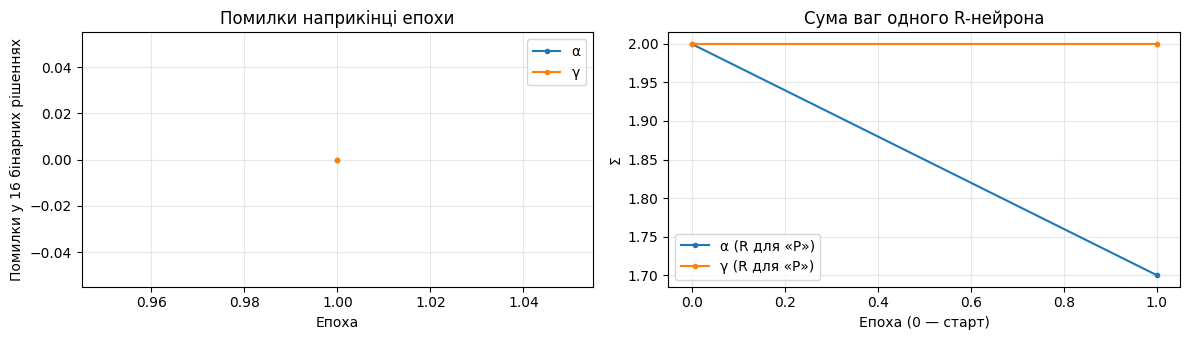

In [14]:
# Графіки помилок, змін ваг, збереження суми
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for label,log in [('α',LOG_ALPHA),('γ',LOG_GAMMA)]:
    axes[0].plot(log['Епоха'],log['Помилки після'],'.-',label=label)
axes[0].set_title('Помилки наприкінці епохи')
axes[0].set_xlabel('Епоха');axes[0].set_ylabel('Помилки у 16 бінарних рішеннях')
for label,sums in [('α',SUM_ALPHA),('γ',SUM_GAMMA)]:
    axes[1].plot(range(len(sums)),sums[:,0],'.-',label=f'{label} (R для «{LETTERS[0]}»)')
axes[1].set_title('Сума ваг одного R-нейрона')
axes[1].set_xlabel('Епоха (0 — старт)');axes[1].set_ylabel('Σ')
for ax in axes: ax.grid(alpha=.3);ax.legend()
plt.tight_layout();plt.show()

,Справжня літера,Змінений індекс S (1..25),Кількість активних A,α-прогноз,γ-прогноз
0,Р,22,0,Невідомо/неоднозначно,Невідомо/неоднозначно
1,О,5,0,Невідомо/неоднозначно,Невідомо/неоднозначно
2,С,1,0,Невідомо/неоднозначно,Невідомо/неоднозначно
3,Т,16,0,Невідомо/неоднозначно,Невідомо/неоднозначно


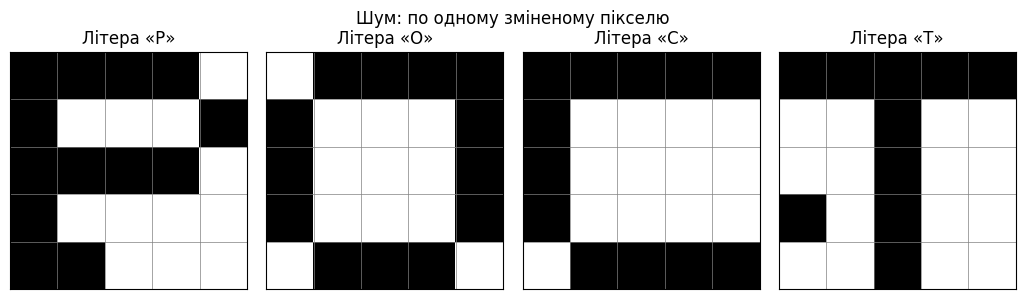

In [15]:
# Виведення результатів для зашумлених пікселів
display(result_noise)
preview_patterns(X_NOISY.reshape(4,5,5),LETTERS,'Шум: по одному зміненому пікселю')

**4.5. Розгорнутий висновок:**

* При $\varepsilon=0.1$ α-система виконала **12** оновлень за **1** епоху, γ-система — **12** оновлень за **1** епоху.
* Кількість правильних розпізнавань на чотирьох навчальних літерах становить **4**/4 (всі 16 бінарних відповідей правильні).
* Для γ-системи $\max\vert{}\Sigma_t-\Sigma_0\vert{}=$ **$1.3323 \times 10^{-15}$** (сума практично незмінна з урахуванням похибки формату з рухомою комою); для α-системи $\max\vert{}\Sigma_t-\Sigma_0\vert{}=$ **$0.3$**.
* При зміні одного пікселя спостерігалося **падіння кількості активних A-нейронів до 0 та результат "Невідомо/неоднозначно"**; причина полягає у **жорстко фіксованому порозі $\theta_{A_k}$ на точний збіг — будь-яка зміна пікселя зменшує зважену суму нижче порогу активації A-детектора**.
* Переваги/обмеження α і γ: **$\alpha$-система простіша в реалізації, але не зберігає загальну суму ваг, тоді як $\gamma$-система суворо підтримує гомеостаз ваг (незмінність суми), проте через консервативність може зіткнутися з недосяжними класифікаціями (наприклад, при сумі ваг 0 та порозі >0)**; наступний крок для підвищення стійкості: **використання менш жорстких порогів активації для A-нейронів (наприклад, $\theta_{A_k} - 2$) або додавання зашумлених прикладів безпосередньо у навчальну вибірку (створення додаткових A-детекторів для варіацій літер)**.


### Місце для власних висновків

**Обрані параметри S/A/R і пояснення:** Обрано сітку 5×5 ($S=25$) для представлення літер "Р, О, С, Т". Використано 4 A-нейрони, кожен з яких налаштовано на розпізнавання рівно однієї літери через точний збіг пікселів. Реалізовано 4 незалежні R-класифікатори за принципом "одна літера проти всіх інших", що дозволяє уникнути неоднозначності класичного перцептрона з єдиним виходом.

**α-система:** кількість епох — **1**; кількість оновлень — **12**; точність — **100% (4/4 літер)**.

**γ-система:** кількість епох — **1**; кількість оновлень — **12**; точність — **100% (4/4 літер)**; чи зберігається сума ваг — **Так (відхилення $1.3323 \times 10^{-15}$ зумовлене машинною точністю)**.

**Поведінка за шуму:** Мережа виявилася абсолютно нестійкою до шуму. Зміна рівно одного випадкового пікселя призвела до нульової активації A-шару, оскільки детектори були налаштовані на точний збіг суми ваг зі встановленим порогом $\theta_{A_k}$.

**Підсумкове порівняння і обмеження мережі:** Обидві системи успішно зійшлися за 1 епоху завдяки ортогональності представлення на A-шарі (кожна літера активує лише свій єдиний A-нейрон). Однак, архітектура виявилася чутливою до зашумлення. $\gamma$-система довела свою властивість зберігати суму ваг, проте має фундаментальне обмеження: за нульової початкової суми та додатного порогу вона не здатна досягти правильної класифікації, що було підтверджено на крайовому контрприкладі.